# High-dim limit of metric MDS under distance concentration

In [1]:
import numpy as np
import pylab as plt
from sklearn.manifold import MDS

plt.style.use('../mpl_style.txt')

In [2]:
n = 10_000
D = np.ones((n, n))
np.fill_diagonal(D, 0)

%time Z = MDS(n_init=1, init="random", verbose=5, metric="precomputed").fit_transform(D)

Iteration 0, stress 8971148.5504
Iteration 1, stress 8911058.8118
Iteration 2, stress 8888895.6082
Iteration 3, stress 8879562.0561
Iteration 4, stress 8875418.8237
Iteration 5, stress 8873526.3506
Iteration 6, stress 8872642.4366
Iteration 7, stress 8872219.7088
Iteration 8, stress 8872011.4051
Iteration 9, stress 8871904.5136
Iteration 10, stress 8871846.5705
Iteration 11, stress 8871812.8836
Convergence criterion reached (iteration 11).
CPU times: user 1min 9s, sys: 1min 49s, total: 2min 59s
Wall time: 1min 37s


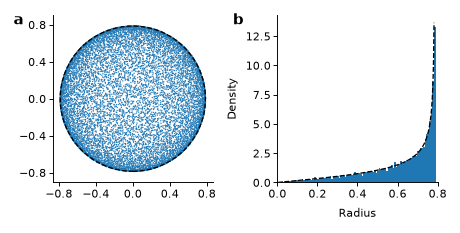

In [3]:
fig = plt.figure(figsize=(3.25, 1.6), layout="constrained")

plt.subplot(121)
plt.axis("equal")
plt.scatter(Z[:, 0], Z[:, 1], s=2, ec="none", rasterized=True)
plt.xticks(np.arange(-.8, .81, .4))
plt.yticks(np.arange(-.8, .81, .4))

c = plt.Circle((0, 0), np.pi / 4, facecolor="none", edgecolor="k", linestyle='--', lw=.7)
plt.gca().add_patch(c)
# c = plt.Circle((0, 0), 2 / np.pi, facecolor="none", edgecolor="k", linestyle='-.', lw=.7)
# plt.gca().add_patch(c)
# c = plt.Circle((0, 0), 45 * np.pi / 128, facecolor="none", edgecolor="k", linestyle=':', lw=.6)
# plt.gca().add_patch(c)
# c = plt.Circle((0, 0), 128 / np.pi / 45, facecolor="none", edgecolor="k", linestyle=':', lw=.7)
# plt.gca().add_patch(c)

plt.subplot(122)
rrr = np.sqrt(np.sum(Z ** 2, axis=1))
plt.hist(rrr, bins=100, density=True);
plt.xlim([0, .8])
plt.xlabel("Radius")
plt.ylabel("Density")

x = np.arange(0, np.pi/4 - 0.003, 0.001)
y = 4 * x / (np.pi * np.sqrt((np.pi / 4) ** 2 - x ** 2))
plt.plot(x, y, 'k--', lw=.7)

fig.text(.00, .93, "a", fontweight="bold", fontsize=8)
fig.text(.50, .93, "b", fontweight="bold", fontsize=8)

fig.savefig("../../figures/limit.png", dpi=300)
fig.savefig("../../figures/limit.pdf", dpi=300)

In [4]:
from sklearn.metrics import pairwise_distances

dd = pairwise_distances(Z)[np.triu_indices(Z.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 0.823, std 0.382, MSE 0.177


In [5]:
R = Z / np.sqrt(np.sum(Z**2, axis=1, keepdims=True)) * np.pi / 4

dd = pairwise_distances(R)[np.triu_indices(Z.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 1.000, std 0.483, MSE 0.234


In [6]:
R = Z / np.sqrt(np.sum(Z**2, axis=1, keepdims=True)) * 2 / np.pi

dd = pairwise_distances(R)[np.triu_indices(Z.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 0.811, std 0.392, MSE 0.189


In [7]:
D = (np.random.rand(*Z.shape) - .5) * 2
r = np.sqrt(np.sum(D**2, axis=1))
D = D[r < 128 / 45 / np.pi]

dd = pairwise_distances(D)[np.triu_indices(D.shape[0], 1)]
print(f"Mean {np.mean(dd):.3f}, std {np.std(dd):.3f}, MSE {np.mean((dd - 1)**2):.3f}")

Mean 0.822, std 0.385, MSE 0.180
